# Notebook 2: Automatic Tissue Type and Histopathological Image Classification (part 2)

In the first notebook, CNN models were developed to classify histopathological images of lung, colon, and breast tissue. Building on that work, this notebook uses MobileNetV2 to develop a tissue identification model that automatically classifies histopathological images into three categories: lung, colon, and breast.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score)
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [2]:
# Main project folder
image_path = Path(r"C:\Users\Hp\Desktop\Cancer_Image_Classification")

# Existing saved dataset splits
split_path = image_path / "splits"

# Folder for trained models
models_path = image_path / "models"

print("Project folder:", image_path.exists())
print("Splits folder:", split_path.exists())
print("Models folder:", models_path.exists())

Project folder: True
Splits folder: True
Models folder: True


In [3]:
lung_train = pd.read_csv(split_path / "lung_train.csv")
colon_train = pd.read_csv(split_path / "colon_train.csv")
breast_train = pd.read_csv(split_path / "breast_train.csv")

print("Lung training images:", len(lung_train))
print("Colon training images:", len(colon_train))
print("Breast training images:", len(breast_train))

Lung training images: 1040
Colon training images: 1041
Breast training images: 280


In [4]:
lung_val = pd.read_csv(split_path / "lung_val.csv")
colon_val = pd.read_csv(split_path / "colon_val.csv")
breast_val = pd.read_csv(split_path / "breast_val.csv")

print("Lung validation images:", len(lung_val))
print("Colon validation images:", len(colon_val))
print("Breast validation images:", len(breast_val))

Lung validation images: 223
Colon validation images: 223
Breast validation images: 60


In [5]:
lung_test = pd.read_csv(split_path / "lung_test.csv")
colon_test = pd.read_csv(split_path / "colon_test.csv")
breast_test = pd.read_csv(split_path / "breast_test.csv")

print("Lung test images:", len(lung_test))
print("Colon test images:", len(colon_test))
print("Breast test images:", len(breast_test))

Lung test images: 224
Colon test images: 224
Breast test images: 60


In [6]:
lung_train["Tissue"] = "lung"
colon_train["Tissue"] = "colon"
breast_train["Tissue"] = "breast"

In [7]:
lung_val["Tissue"] = "lung"
colon_val["Tissue"] = "colon"
breast_val["Tissue"] = "breast"

In [8]:
lung_test["Tissue"] = "lung"
colon_test["Tissue"] = "colon"
breast_test["Tissue"] = "breast"

In [9]:
display(lung_train.head())

,Image Path,Label,Tissue
0,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_n,lung
1,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_scc,lung
2,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca,lung
3,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca,lung
4,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca,lung


In [10]:
tissue_train = pd.concat(
    [lung_train, colon_train, breast_train],
    ignore_index=True
)

print("Total training images:", len(tissue_train))

Total training images: 2361


In [11]:
tissue_val = pd.concat(
    [lung_val, colon_val, breast_val],
    ignore_index=True
)

print("Total validation images:", len(tissue_val))

Total validation images: 506


In [12]:
tissue_test = pd.concat(
    [lung_test, colon_test, breast_test],
    ignore_index=True
)

print("Total testing images:", len(tissue_test))

Total testing images: 508


In [13]:
print("Training:")
print(tissue_train["Tissue"].value_counts())

print("\nValidation:")
print(tissue_val["Tissue"].value_counts())

print("\nTesting:")
print(tissue_test["Tissue"].value_counts())

Training:
Tissue
colon     1041
lung      1040
breast     280
Name: count, dtype: int64

Validation:
Tissue
lung      223
colon     223
breast     60
Name: count, dtype: int64

Testing:
Tissue
lung      224
colon     224
breast     60
Name: count, dtype: int64


Fewer breast images than lung and colon images are in the dataset. This class imbalance will be account during model training.

In [14]:
tissue_class_names = ["breast", "colon", "lung"]

tissue_label_map = {
    name: index
    for index, name in enumerate(tissue_class_names)
}

print(tissue_label_map)

{'breast': 0, 'colon': 1, 'lung': 2}


In [15]:
def load_tissue_image(path, label):
    def read_image(path_value):
        path_str = path_value.numpy().decode("utf-8")

        with Image.open(path_str) as img:
            img = img.convert("RGB")
            img = img.resize((224, 224))

            return np.array(img, dtype=np.float32)

    image = tf.py_function(
        func=read_image,
        inp=[path],
        Tout=tf.float32
    )

    image.set_shape((224, 224, 3))

    return image, label

In [16]:
def create_tissue_dataset(df, training=False):

    paths = df["Image Path"].values

    labels = df["Tissue"].map(tissue_label_map).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42
        )

    dataset = dataset.map(
        load_tissue_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(32)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


In [17]:
# Prepare the three TensorFlow datasets

tissue_train_ds = create_tissue_dataset(tissue_train, training=True)

tissue_val_ds = create_tissue_dataset(tissue_val)

tissue_test_ds = create_tissue_dataset(tissue_test)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [19]:
# Check image and label shapes 
# Take one batch from the training dataset

for images, labels in tissue_train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32,)


In [20]:
# Check the labels and pixel values
for images, labels in tissue_train_ds.take(1):
    print("First 10 labels:", labels.numpy()[:10])
    print("Minimum pixel value:", images.numpy().min())
    print("Maximum pixel value:", images.numpy().max())

First 10 labels: [1 1 1 1 1 2 1 1 1 2]
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [22]:
# Handling Class Imbalance
from sklearn.utils.class_weight import compute_class_weight

# Convert tissue names into numerical labels
y_train = tissue_train["Tissue"].map(tissue_label_map).values

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=y_train
)

class_weights = dict(enumerate(weights))

print("Class weights:", class_weights)

Class weights: {0: np.float64(2.8107142857142855), 1: np.float64(0.7560038424591738), 2: np.float64(0.7567307692307692)}


In [23]:
# Load MobileNetV2 pretrained on ImageNet

base_tissue_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")

# Freeze the pretrained layers
base_tissue_model.trainable = False

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [24]:
tissue_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Prepare pixel values for MobileNetV2
    layers.Rescaling(1./127.5, offset=-1),

    # Pretrained CNN
    base_tissue_model,

    # New classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Predict one of three tissue types
    layers.Dense(3, activation="softmax")
])

In [25]:
tissue_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print("Tissue identification model compiled successfully!")

Tissue identification model compiled successfully!


In [26]:
tissue_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [27]:
# Configure early stopping
tissue_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Save the best model during training
tissue_checkpoint = ModelCheckpoint(
    filepath=str(models_path / "tissue_mobilenetv2_best.keras"),
    monitor="val_loss",
    save_best_only=True
)

In [28]:
# Train the tissue identification model

tissue_history = tissue_model.fit(
    tissue_train_ds,
    validation_data=tissue_val_ds,
    epochs=20,
    class_weight=class_weights,
    callbacks=[tissue_early_stopping, tissue_checkpoint],
    verbose=1
)

C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.9191 - loss: 0.2152 - val_accuracy: 0.9585 - val_loss: 0.1279
Epoch 2/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 72s 970ms/step - accuracy: 0.9835 - loss: 0.0481 - val_accuracy: 0.9763 - val_loss: 0.0547
Epoch 3/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.9903 - loss: 0.0247 - val_accuracy: 0.9822 - val_loss: 0.0532
Epoch 4/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.9958 - loss: 0.0170 - val_accuracy: 0.9842 - val_loss: 0.0549
Epoch 5/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 67s 910ms/step - accuracy: 0.9970 - loss: 0.0123 - val_accuracy: 0.9901 - val_loss: 0.0403
Epoch 6/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 69s 933ms/step - accuracy: 0.9983 - loss: 0.0072 - val_accuracy: 0.9881 - val_loss: 0.0426
Epoch 7/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 68s 919ms/step - accuracy: 0.9983 - loss: 0.0061 - val_accuracy: 0.9921 - val_loss: 0.0522
Epoch 8/20
74/74 ━━━━━━━━━━━━━━━━━━━━ 71s 960ms/step - accuracy: 0.9979 - loss: 0.0055 - val_accuracy: 0.9

In [29]:
# Evaluate the tissue identification model

tissue_test_loss, tissue_test_accuracy = tissue_model.evaluate(
    tissue_test_ds
)

print(f"Test Accuracy: {tissue_test_accuracy:.2%}")
print(f"Test Loss: {tissue_test_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 738ms/step - accuracy: 0.9941 - loss: 0.0183
Test Accuracy: 99.41%
Test Loss: 0.0183


MobileNetV2 tissue identification model achieved 99.41% test accuracy.

In [30]:
# Predict tissue types for test images
tissue_prob = tissue_model.predict(tissue_test_ds)

# Select the class with the highest probability
tissue_pred = np.argmax(tissue_prob, axis=1)

# Get the actual tissue labels
tissue_true = np.concatenate([
    labels.numpy() for images, labels in tissue_test_ds
])

print("Predictions:", len(tissue_pred))
print("Actual labels:", len(tissue_true))

16/16 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step  
Predictions: 508
Actual labels: 508


In [31]:
tissue_cm = confusion_matrix(
    tissue_true,
    tissue_pred,
    labels=[0, 1, 2]
)

print(tissue_cm)

[[ 60   0   0]
 [  0 223   1]
 [  0   2 222]]


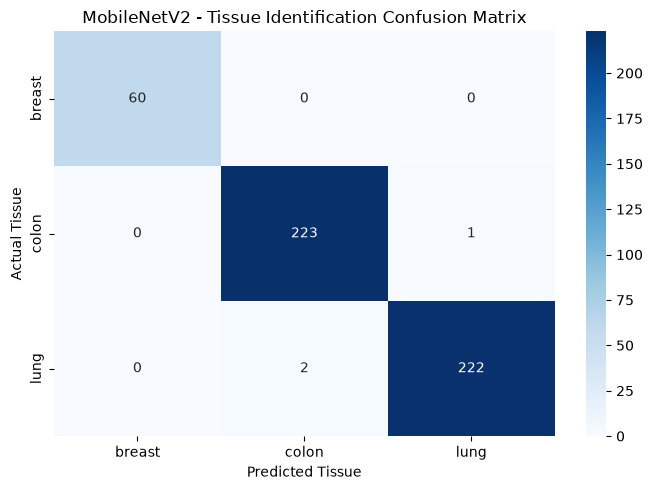

In [32]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    tissue_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=tissue_class_names,
    yticklabels=tissue_class_names
)

plt.title("MobileNetV2 - Tissue Identification Confusion Matrix")
plt.xlabel("Predicted Tissue")
plt.ylabel("Actual Tissue")

plt.tight_layout()
plt.show()

Confusion matrix confirms that only 3 out of 508 test images were incorrectly classified.

In [33]:
# Generate the tissue identification classification report

print(classification_report(
    tissue_true,
    tissue_pred,
    target_names=tissue_class_names,
    digits=4
))

              precision    recall  f1-score   support

      breast     1.0000    1.0000    1.0000        60
       colon     0.9911    0.9955    0.9933       224
        lung     0.9955    0.9911    0.9933       224

    accuracy                         0.9941       508
   macro avg     0.9955    0.9955    0.9955       508
weighted avg     0.9941    0.9941    0.9941       508



In [34]:
# Check for identical image paths across dataset splits

train_paths = set(tissue_train["Image Path"])
val_paths = set(tissue_val["Image Path"])
test_paths = set(tissue_test["Image Path"])

print("Train / Validation overlap:", len(train_paths & val_paths))
print("Train / Test overlap:", len(train_paths & test_paths))
print("Validation / Test overlap:", len(val_paths & test_paths))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


### Conclusion:
The MobileNetV2 tissue identification model achieved 99.41% accuracy correctly classifying 505 of 508 histopathological images. These results demonstrate strong performance in distinguishing breast, colon, and lung tissue within the available dataset. However, further evaluation using independent image sources is necessary to assess the model's generalization ability.

In [35]:
# Save the trained tissue identification model
tissue_model.save(models_path / "tissue_mobilenetv2_final.keras")

print("Model 4 saved successfully!")

Model 4 saved successfully!
